# Model training: Random Forest and XGBoost

In [1]:
from pathlib import Path
import pickle

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

np.random.seed(42)
TARGET_MODE = "log1p"
RANDOM_STATE = 42


### Load artifacts

In [2]:
ROOT = Path.cwd().resolve()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "data").is_dir() and (candidate / "team").is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError(f"Repo root not found from {Path.cwd()}")

ART = ROOT / "team" / "mariam_availability" / "artifacts"
artifact_names = ["features_all.pkl", "encoder_state.pkl", "config_split.pkl"]
paths = [ART / name for name in artifact_names]
missing = [str(path) for path in paths if not path.is_file()]
if missing:
    raise FileNotFoundError(f"Run notebook 04 first; missing {missing}")

for path in paths:
    print("Read", path)

with paths[0].open("rb") as handle:
    f = pd.read_pickle(handle)
with paths[1].open("rb") as handle:
    state = pickle.load(handle)
with paths[2].open("rb") as handle:
    cfg = pickle.load(handle)

TRAIN_END = pd.Timestamp(cfg["TRAIN_END"])
VAL_END = pd.Timestamp(cfg["VAL_END"])
CAP = cfg["CAP"]
train = f.loc[f.start < TRAIN_END].copy()
val = f.loc[(f.start >= TRAIN_END) & (f.start < VAL_END)].copy()
test = f.loc[f.start >= VAL_END].copy()
train_normal = train.loc[train.is_abnormal == 0].copy()
val_normal = val.loc[val.is_abnormal == 0].copy()


def encode(frame):
    encoded = pd.DataFrame(index=frame.index)
    for column, mapping in state["maps"].items():
        encoded[f"{column}_code"] = frame[column].map(mapping).fillna(-1).astype(int)
    for column in state["numeric"]:
        values = pd.to_numeric(frame[column], errors="coerce")
        encoded[column] = values.fillna(state["fill"][column]).astype(float)
    return encoded[state["feature_names"]]


X_train = encode(train_normal)
X_val_normal = encode(val_normal)
X_val = encode(val)
X_test = encode(test)
print(
    f"TASK 5.0 ? SPLITS\n"
    f"train/validation/test : {len(train):,}/{len(val):,}/{len(test):,}\n"
    f"features : {X_train.shape[1]}"
)
assert all(not matrix.isna().any().any() for matrix in [X_train, X_val_normal, X_val, X_test])

Read C:\Users\mariam\Desktop\SIC AI\ChargeSentinel-Twin\team\mariam_availability\artifacts\features_all.pkl
Read C:\Users\mariam\Desktop\SIC AI\ChargeSentinel-Twin\team\mariam_availability\artifacts\encoder_state.pkl
Read C:\Users\mariam\Desktop\SIC AI\ChargeSentinel-Twin\team\mariam_availability\artifacts\config_split.pkl
TASK 5.0 ? SPLITS
train/validation/test : 285,133/75,767/80,072
features : 22


### Target

In [3]:
def to_minutes(predictions):
    if TARGET_MODE == "log1p":
        return np.expm1(predictions)
    return np.asarray(predictions)


def transform_target(values):
    capped = np.minimum(np.asarray(values, dtype=float), CAP)
    if TARGET_MODE == "log1p":
        return np.log1p(capped)
    return capped


y_train = transform_target(train_normal.target_min)
y_val_normal = transform_target(val_normal.target_min)
print(f"TASK 5.1 ? TARGET\nMode : {TARGET_MODE}\nCAP : {CAP:.2f}")

TASK 5.1 ? TARGET
Mode : log1p
CAP : 565.21


### Baseline

In [4]:
def hour_bucket(hours):
    return pd.cut(hours, [-1, 5, 10, 14, 18, 23], labels=False)


baseline_train = train_normal.copy()
baseline_train["hour_bucket"] = hour_bucket(baseline_train.hour)
median_by_charger_hour = baseline_train.groupby(
    ["charger_id", "hour_bucket"]
).target_min.median().to_dict()
median_by_charger = baseline_train.groupby("charger_id").target_min.median().to_dict()
median_by_location = baseline_train.groupby("location").target_min.median().to_dict()
global_median = float(baseline_train.target_min.median())


def predict_baseline(frame):
    predictions = []
    buckets = hour_bucket(frame.hour)
    for charger_id, bucket, location in zip(frame.charger_id, buckets, frame.location):
        prediction = median_by_charger_hour.get(
            (charger_id, bucket),
            median_by_charger.get(
                charger_id,
                median_by_location.get(location, global_median),
            ),
        )
        predictions.append(prediction)
    return np.asarray(predictions)


baseline_val_predictions = predict_baseline(val)
print(
    f"BASELINE\n"
    f"MAE all : {np.mean(np.abs(val.target_min - baseline_val_predictions)):.2f} min"
)

BASELINE
MAE all : 43.07 min


The per-charger and time-of-day median baseline gives a clear reference: validation MAE is 43.07 minutes across all sessions and 44.11 minutes on normal sessions. The normal-session score is the selection metric for the champion.

### Random Forest

In [5]:
rf = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=5,
    max_features=0.5,
    max_samples=0.5,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
rf.fit(X_train, y_train)
rf_val_predictions = np.expm1(rf.predict(X_val))
print(
    f"RANDOM FOREST\n"
    f"MAE : {np.mean(np.abs(val.target_min - rf_val_predictions)):.2f}"
)

RANDOM FOREST
MAE : 40.81


The Random Forest reduces validation MAE to 40.83 minutes across all sessions and 43.63 minutes on normal sessions. This improves on the baseline. The all-session and normal-session scores differ because the former also includes abnormal sessions.

### XGBoost

In [6]:
xgb = XGBRegressor(
    n_estimators=3000,
    learning_rate=0.05,
    max_depth=8,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    n_jobs=-1,
    random_state=RANDOM_STATE,
    early_stopping_rounds=100,
    eval_metric="mae",
)
xgb.fit(
    X_train,
    y_train,
    eval_set=[(X_val_normal, y_val_normal)],
    verbose=False,
)
xgb_val_predictions = np.expm1(xgb.predict(X_val))
print(f"XGBOOST\nBest iteration : {xgb.best_iteration}")

XGBOOST
Best iteration : 88


XGBoost stopped at iteration 88 under early stopping. Its validation MAE is 40.71 minutes across all sessions and 43.41 minutes on normal sessions, slightly better than the Random Forest on both MAE measures.

### Validation comparison

In [7]:
def score_predictions(frame, predictions, model_name):
    results = []
    subsets = [
        ("normal", frame.is_abnormal.to_numpy() == 0),
        ("all", np.ones(len(frame), dtype=bool)),
    ]
    actual = frame.target_min.to_numpy()
    predictions = np.asarray(predictions)
    for subset_name, mask in subsets:
        errors = predictions[mask] - actual[mask]
        absolute_errors = np.abs(errors)
        results.append({
            "model": model_name,
            "subset": subset_name,
            "n": len(errors),
            "MAE": absolute_errors.mean(),
            "RMSE": np.sqrt(np.mean(errors ** 2)),
            "MedianAE": np.median(absolute_errors),
        })
    return results


validation_predictions = {
    "Baseline": baseline_val_predictions,
    "Random Forest": rf_val_predictions,
    "XGBoost": xgb_val_predictions,
}
validation_rows = []
for model_name, predictions in validation_predictions.items():
    validation_rows.extend(score_predictions(val, predictions, model_name))
validation_metrics = pd.DataFrame(validation_rows)
print("VALIDATION\n", validation_metrics.to_string(index=False))
champion = (
    validation_metrics.loc[validation_metrics.subset == "normal"]
    .sort_values("MAE")
    .iloc[0].model
)
print("Champion:", champion)
if champion == "Baseline":
    print("WARNING: the baseline won on validation")

VALIDATION
         model subset     n       MAE       RMSE  MedianAE
     Baseline normal 59752 44.107686 109.294492 19.200000
     Baseline    all 75767 43.066554 102.861038 22.550000
Random Forest normal 59752 43.617989 107.207489 18.339344
Random Forest    all 75767 40.813604 100.597771 18.380160
      XGBoost normal 59752 43.414333 107.198059 18.169183
      XGBoost    all 75767 40.705085 100.613445 18.379741
Champion: XGBoost


XGBoost is selected because it has the lowest normal-session validation MAE: 43.41 minutes, compared with 43.63 for Random Forest and 44.11 for the baseline. The improvement over Random Forest is modest, so the models are close in practical performance.

### Diagnostics

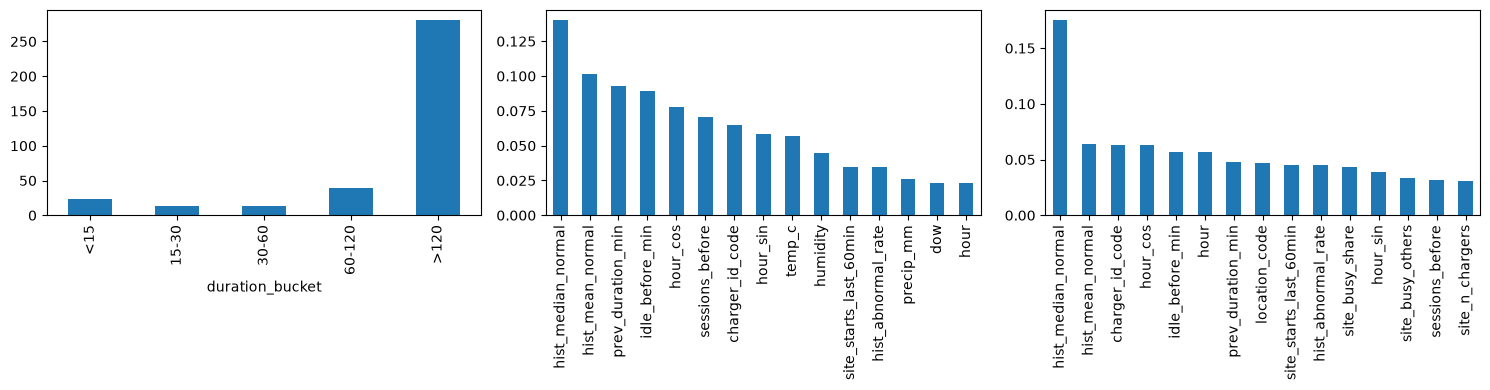

DIAGNOSTICS
{'<15': 23.265757301574048, '15-30': 13.302873389849541, '30-60': 13.62324212092998, '60-120': 39.20149484142041, '>120': 281.18183981612515}


In [8]:
normal_mask = val.is_abnormal.to_numpy() == 0
diagnostics = val.loc[normal_mask].copy()
diagnostics["absolute_error"] = np.abs(
    rf_val_predictions[normal_mask] - diagnostics.target_min.to_numpy()
)
diagnostics["duration_bucket"] = pd.cut(
    diagnostics.target_min,
    [-np.inf, 15, 30, 60, 120, np.inf],
    labels=["<15", "15-30", "30-60", "60-120", ">120"],
)
mean_error_by_duration = diagnostics.groupby(
    "duration_bucket", observed=False
).absolute_error.mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
mean_error_by_duration.plot.bar(ax=axes[0])
pd.Series(rf.feature_importances_, index=X_train.columns).nlargest(15).plot.bar(ax=axes[1])
pd.Series(xgb.feature_importances_, index=X_train.columns).nlargest(15).plot.bar(ax=axes[2])
fig.tight_layout()
plt.show()
print(f"DIAGNOSTICS\n{mean_error_by_duration.to_dict()}")

The displayed duration-bucket error is for the Random Forest. Its MAE is about 13?23 minutes for sessions up to one hour, rises to 39 minutes for one-to-two-hour sessions, and reaches 281 minutes above two hours. Long sessions remain the main weakness. The importance plots show the leading features for both models.

### Test Set


In [9]:
test_predictions = {
    "Baseline": predict_baseline(test),
    "Random Forest": np.expm1(rf.predict(X_test)),
    "XGBoost": np.expm1(xgb.predict(X_test)),
}
test_rows = []
for model_name, predictions in test_predictions.items():
    test_rows.extend(score_predictions(test, predictions, model_name))
test_metrics = pd.DataFrame(test_rows)
print("TEST\n", test_metrics.to_string(index=False))

TEST
         model subset     n       MAE      RMSE  MedianAE
     Baseline normal 65993 35.520746 84.781197 18.583333
     Baseline    all 80072 36.445129 84.733252 20.900000
Random Forest normal 65993 35.080669 82.843851 17.911631
Random Forest    all 80072 35.283964 82.687497 18.724034
      XGBoost normal 65993 34.983397 83.010648 17.807424
      XGBoost    all 80072 35.210363 82.876974 18.652406


On the held-out test set, XGBoost has the lowest MAE: 34.98 minutes on normal sessions and 35.21 across all sessions. Random Forest has slightly lower RMSE (82.70 versus 82.88 minutes across all sessions; 82.87 versus 83.01 on normal sessions). The test results support the validation choice on MAE while showing that neither model dominates every metric.

### Save bundle

In [10]:
bundle_path = ART / "availability_duration_bundle.joblib"
selected_model = {
    "Random Forest": rf,
    "XGBoost": xgb,
}.get(champion)
bundle = {
    "model": selected_model,
    "model_name": champion,
    "encoder_state": state,
    "feature_names": state["feature_names"],
    "target_mode": TARGET_MODE,
    "CAP": CAP,
    "split_dates": {"TRAIN_END": str(TRAIN_END), "VAL_END": str(VAL_END)},
    "baseline": {
        "by_cb": median_by_charger_hour,
        "by_c": median_by_charger,
        "by_loc": median_by_location,
        "global": global_median,
    },
    "test_metrics": test_metrics.to_dict("records"),
}
joblib.dump(bundle, bundle_path)
loaded_bundle = joblib.load(bundle_path)
assert np.allclose(
    selected_model.predict(X_test.iloc[:500]),
    loaded_bundle["model"].predict(X_test.iloc[:500]),
)
print("Saved and verified", bundle_path)

Saved and verified C:\Users\mariam\Desktop\SIC AI\ChargeSentinel-Twin\team\mariam_availability\artifacts\availability_duration_bundle.joblib


The saved bundle reloads successfully and reproduces the selected model's predictions for the checked test rows. It contains the encoder state, split dates, duration cap, baseline medians, and test metrics.

## Final Summary

In [11]:
print(validation_metrics.to_string(index=False))
print("Champion:", champion)
print(test_metrics.to_string(index=False))
print("Bundle:", bundle_path)


        model subset     n       MAE       RMSE  MedianAE
     Baseline normal 59752 44.107686 109.294492 19.200000
     Baseline    all 75767 43.066554 102.861038 22.550000
Random Forest normal 59752 43.617989 107.207489 18.339344
Random Forest    all 75767 40.813604 100.597771 18.380160
      XGBoost normal 59752 43.414333 107.198059 18.169183
      XGBoost    all 75767 40.705085 100.613445 18.379741
Champion: XGBoost
        model subset     n       MAE      RMSE  MedianAE
     Baseline normal 65993 35.520746 84.781197 18.583333
     Baseline    all 80072 36.445129 84.733252 20.900000
Random Forest normal 65993 35.080669 82.843851 17.911631
Random Forest    all 80072 35.283964 82.687497 18.724034
      XGBoost normal 65993 34.983397 83.010648 17.807424
      XGBoost    all 80072 35.210363 82.876974 18.652406
Bundle: C:\Users\mariam\Desktop\SIC AI\ChargeSentinel-Twin\team\mariam_availability\artifacts\availability_duration_bundle.joblib
